# 05 — Final results and error analysis
Consolidated verified results. This notebook requires only published report files, not raw dataset images or GPU inference.

This notebook synthesizes RQ1–RQ3 and the threshold and error analyses reported in Chapters 6–10.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORT = ROOT / 'reports'
FIG = REPORT / 'publication_assets/figures'
conditions = ['original','brightness_085','brightness_070','blur_075','blur_150']
variants = ['rotation_only','brightness','blur','combined']
metrics = ['image_auroc','image_ap','image_f1max','pixel_auroc','pixel_f1max','pixel_aupro']
import json
base = pd.read_csv(REPORT/'baseline_reproduction/per_run.csv')
rob = pd.read_csv(REPORT/'lighting_blur/per_run.csv')
imp = pd.read_csv(REPORT/'reference_augmentation/per_run.csv')
cal = pd.read_csv(REPORT/'threshold_calibration/per_run.csv')
audit = json.loads((REPORT/'final_scientific_analysis/audit.json').read_text())
assert (len(base),len(rob),len(imp),len(cal))==(45,180,900,225)
assert audit['verified_runs']==900
print('Verified report rows: 45 baseline, 180 perturbed, 900 ablation, 225 threshold comparisons.')


Verified report rows: 45 baseline, 180 perturbed, 900 ablation, 225 threshold comparisons.


## 1. Baseline reproduction and controlled robustness

In [2]:
display((100*base.groupby('category')[metrics].mean().mean()).round(2).rename('Percent'))
display(rob.groupby('condition')[[m+'_change_pp' for m in metrics]].mean().round(3))


image_auroc    96.52
image_ap       98.14
image_f1max    95.96
pixel_auroc    96.26
pixel_f1max    57.94
pixel_aupro    91.72
Name: Percent, dtype: float64

,image_auroc_change_pp,image_ap_change_pp,image_f1max_change_pp,pixel_auroc_change_pp,pixel_f1max_change_pp,pixel_aupro_change_pp
condition,,,,,,
blur_075,-0.659,-0.412,-0.484,-0.178,-0.648,-0.482
blur_150,-3.077,-1.980,-2.274,-0.787,-2.149,-1.528
brightness_070,-0.058,-0.027,-0.075,-0.026,-0.063,-0.124
brightness_085,0.105,0.084,0.082,0.007,0.038,0.005


## 2. Frozen normal-only threshold calibration
Forty normal training images per category, excluding the three reference images. The 39th ordered score defines a threshold for each of the 45 category/reference pairs. Apply the same threshold to original and perturbed test images. This analysis is for the rotation-only baseline, not the augmented method.

,fpr,fnr,tpr
condition,,,
original,8.32,17.03,82.97
brightness_085,8.46,17.11,82.89
brightness_070,8.48,17.20,82.80
blur_075,9.84,17.92,82.08
blur_150,20.34,16.38,83.62


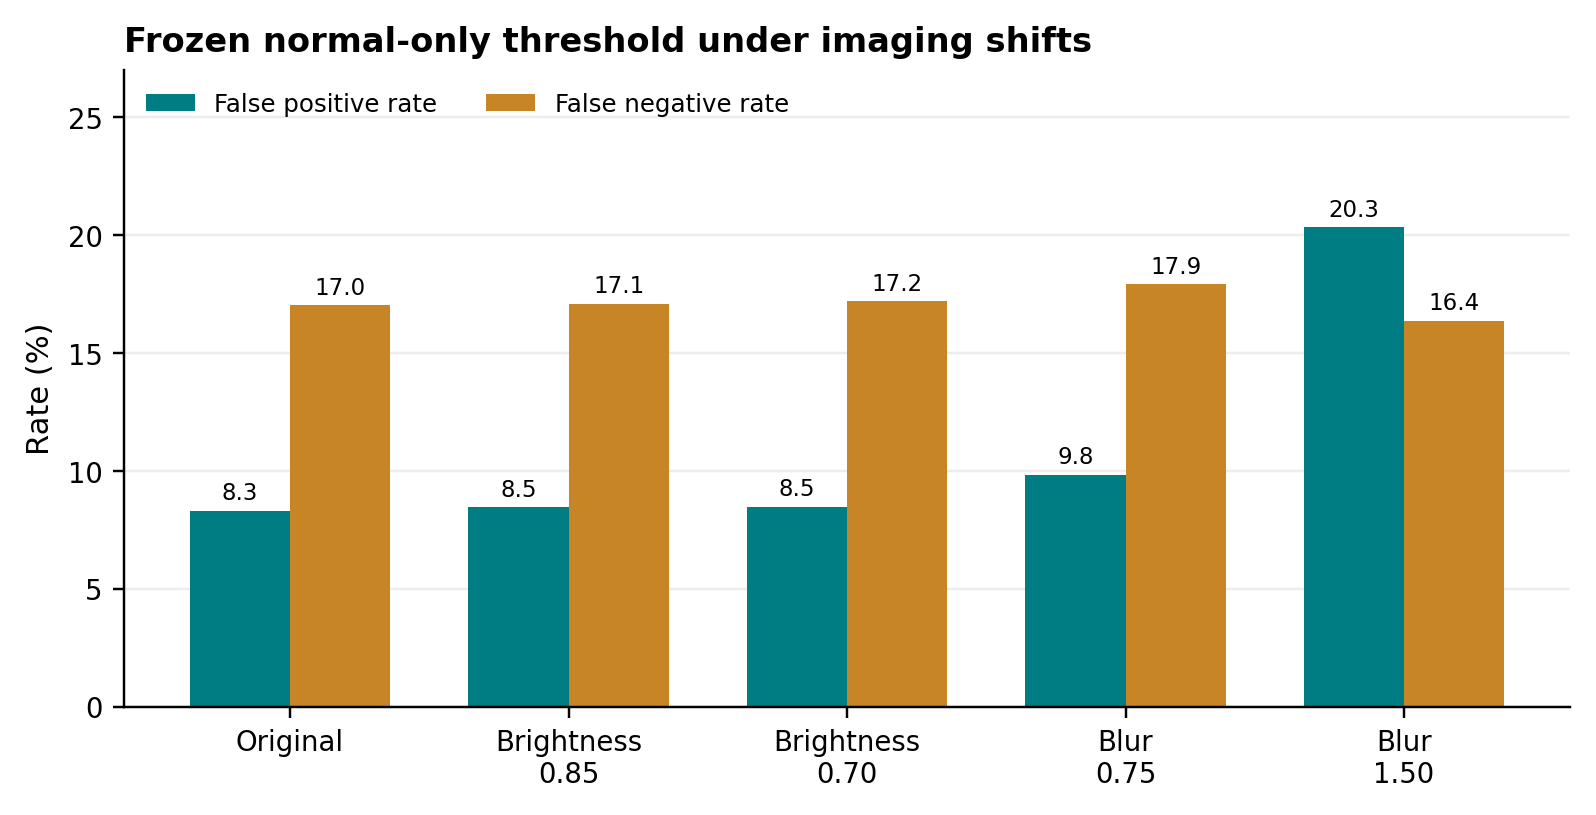

In [3]:
import sys
from tempfile import mkdtemp
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.visualize import generate_publication_assets
output = ROOT / "outputs/notebook_figures"
output.mkdir(parents=True, exist_ok=True)
generated = generate_publication_assets(Path(mkdtemp(prefix="calibration_", dir=output)) / "publication_assets", study="calibration")
FIG = generated["figures"]
assert cal.groupby(['category','seed']).threshold.nunique().eq(1).all()
assert not cal.duplicated(['category','seed','condition']).any()
assert cal.groupby(['category','seed']).condition.nunique().eq(5).all()
assert np.allclose(cal.fp/cal.normal,cal.fpr) and np.allclose(cal.fn/cal.anomalous,cal.fnr)
display((100*cal.groupby('condition')[['fpr','fnr','tpr']].mean().loc[conditions]).round(2))
display(Image(filename=str(FIG/'05_threshold_calibration.png')))


## 3. Paired augmentation results

The reference-sensitivity figure is generated in Notebook 04 and reused here.

,image_auroc_delta_pp,pixel_aupro_delta_pp
condition,,
original,0.078,-0.104
brightness_085,0.068,-0.099
brightness_070,0.049,-0.098
blur_075,0.321,-0.036
blur_150,1.540,0.157


,image_auroc_delta_pp,pixel_aupro_delta_pp
seed,,
0,1.704,0.182
1,1.616,0.214
2,1.301,0.075


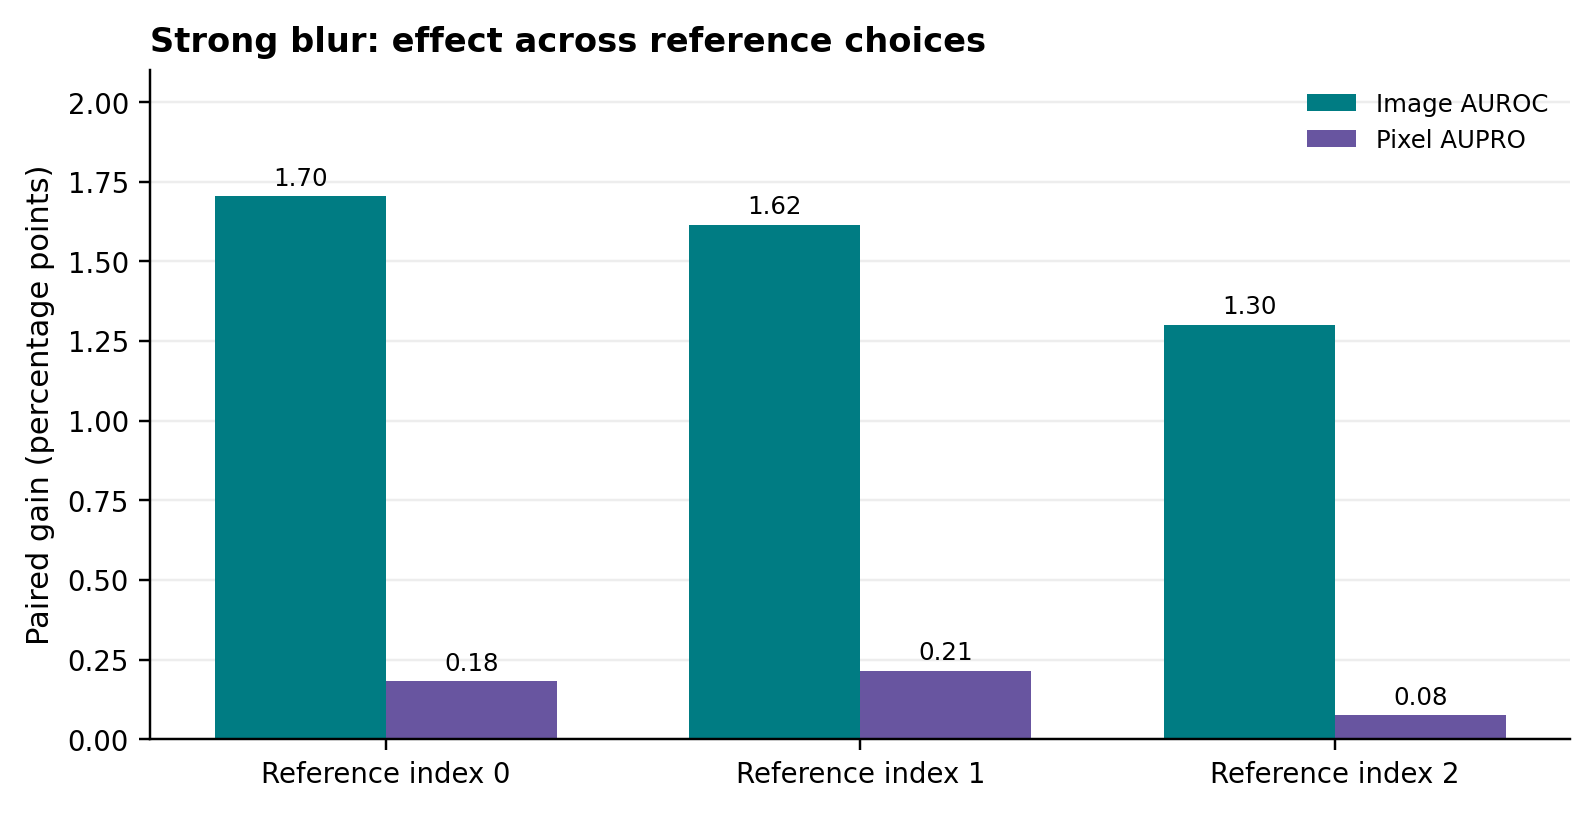

In [4]:
a = imp[imp.variant=='blur']
display(a.groupby('condition')[['image_auroc_delta_pp','pixel_aupro_delta_pp']].mean().loc[conditions].round(3))
display(a[a.condition=='blur_150'].groupby('seed')[['image_auroc_delta_pp','pixel_aupro_delta_pp']].mean().round(3))
display(Image(filename=str(REPORT/'publication_assets/figures/06_reference_sensitivity.png')))


## 4. Selected error cases and archived comparator parity

In [5]:
display(pd.read_csv(REPORT/'lighting_blur/selected_blur_cases.csv'))
display(pd.Series(audit['archive_max_abs_metric_delta_pp']).rename('Maximum absolute difference (pp)'))
print('Largest localized raw map difference:',audit['archive_max_map_error'])


,category,reference_index,test_image,original_score,blur_150_score,change
0,transistor,2,good/046.png,0.219563,0.446366,0.226803
1,transistor,0,misplaced/000.png,0.416526,0.332696,-0.083830
2,screw,2,thread_side/022.png,0.351776,0.219423,-0.132353
3,cable,2,poke_insulation/003.png,0.601771,0.444713,-0.157058


image_auroc_archive_delta_pp    0.000000
image_ap_archive_delta_pp       0.000000
image_f1max_archive_delta_pp    0.000000
pixel_auroc_archive_delta_pp    0.000277
pixel_f1max_archive_delta_pp    0.000082
pixel_aupro_archive_delta_pp    0.001012
Name: Maximum absolute difference (pp), dtype: float64

Largest localized raw map difference: 0.1692559123039245


**Conclusions and limitations.** Strong blur reduces baseline image AUROC by 3.08 pp and increases fixed-threshold false alarms by 12.02 pp. Fixed-budget blur augmentation mitigates the ranking loss, but its effect on fixed-threshold false alarms has not been measured. Localization improvements are small and heterogeneous (Zipper loses AUPRO). The two Screw strong-blur localized map differences are disclosed; image-level metrics match the archive and maximum per-run AUPRO difference is 0.001012 pp. The study is limited to MVTec AD, one-shot reference selection and digital perturbations. The empirical scope is one-shot detection. Zero-shot methods are discussed as related work, not evaluated experimentally.